In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kritikseth/fruit-and-vegetable-image-recognition")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
Path to dataset files: /kaggle/input/fruit-and-vegetable-image-recognition


In [ ]:
path

'/kaggle/input/fruit-and-vegetable-image-recognition'

In [ ]:
import os  #  operating system

In [ ]:
os.listdir(path)

['validation', 'test', 'train']

In [ ]:
os.listdir(path)[0]

'validation'

In [ ]:
valid_path = os.path.join(path, os.listdir(path)[0])

In [ ]:
test_path = os.path.join(path, os.listdir(path)[1])

In [ ]:
train_path = os.path.join(path, os.listdir(path)[2])

In [ ]:
print(train_path)
print(test_path)
print(valid_path)

/kaggle/input/fruit-and-vegetable-image-recognition/train
/kaggle/input/fruit-and-vegetable-image-recognition/test
/kaggle/input/fruit-and-vegetable-image-recognition/validation


In [ ]:
sweet_corn = os.path.join(train_path, os.listdir(train_path)[10])

In [ ]:
plot_sweet_corn = os.path.join(sweet_corn,os.listdir(sweet_corn)[7])

In [ ]:
from IPython import display

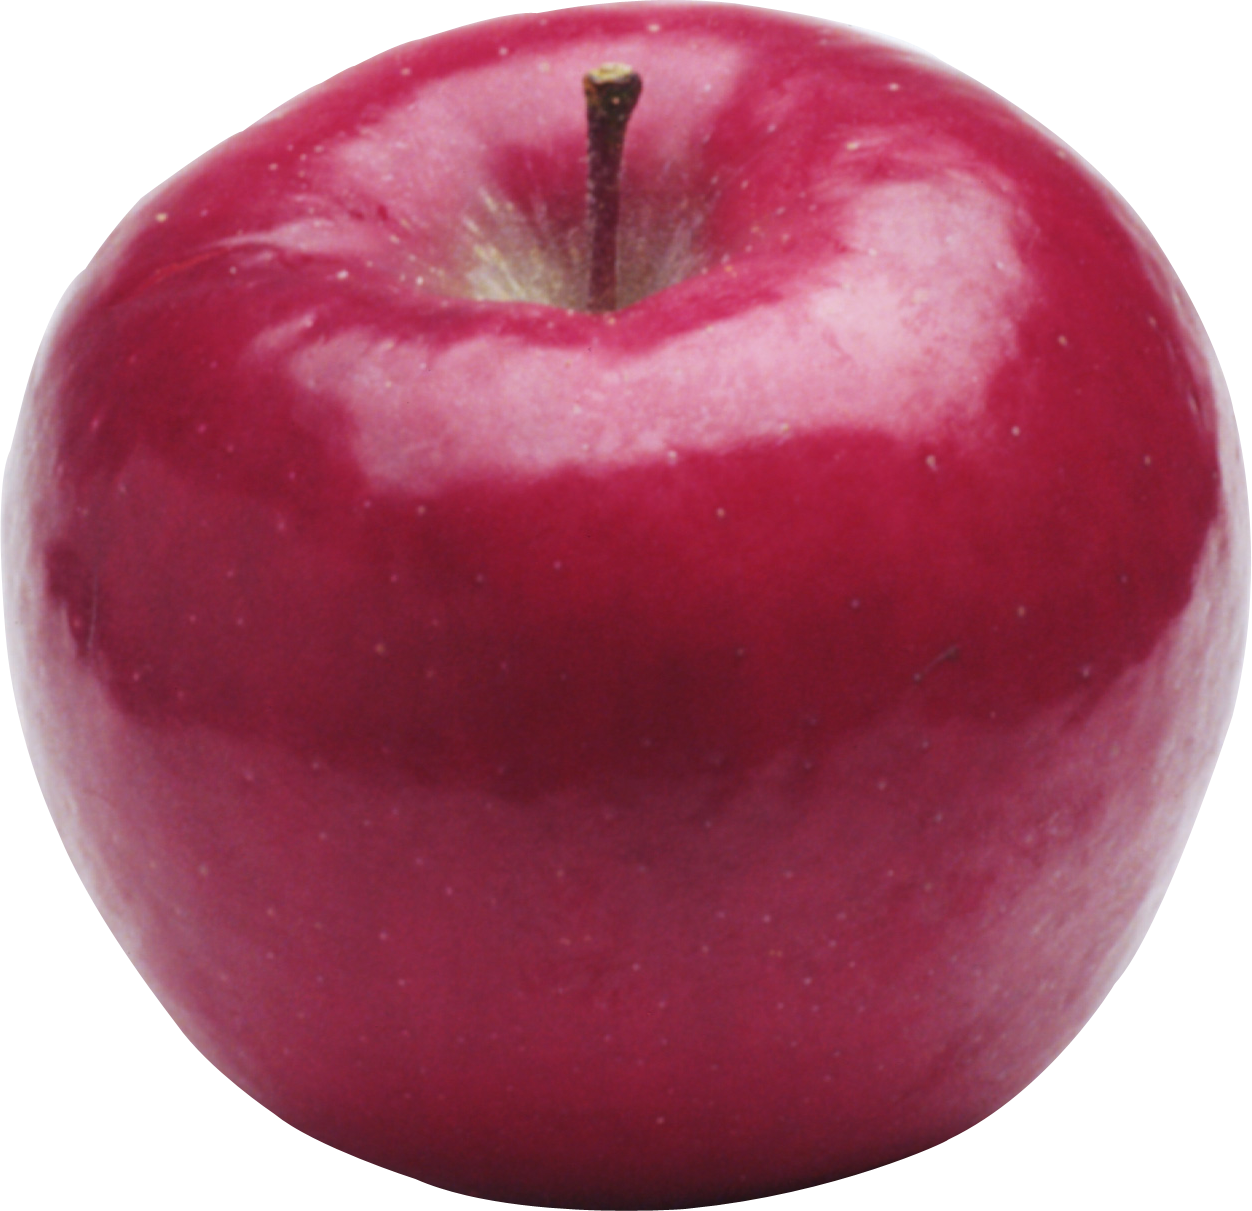

In [ ]:
display.Image(plot_sweet_corn)

In [ ]:
train_path

'/kaggle/input/fruit-and-vegetable-image-recognition/train'

In [ ]:
import tensorflow as tf

In [ ]:
train_data= tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(128, 128),
    shuffle = True

)

Found 3115 files belonging to 36 classes.


In [ ]:
test_data= tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(128, 128),
    shuffle = True

)

Found 359 files belonging to 36 classes.


In [ ]:
valid_data= tf.keras.utils.image_dataset_from_directory(
    valid_path,
    image_size=(128, 128),
    shuffle = True

)

Found 351 files belonging to 36 classes.


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
model =keras.Sequential([
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3,3), activation="relu"),
    layers.MaxPool2D((2,2)),

    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPool2D((2,2)),

    layers.Conv2D(128, (3,3), activation="relu"),
    layers.MaxPool2D((2,2)),  # features ko exttract krna
    layers.Flatten(),


    layers.Dense(128, activation="relu"),
    layers.Dense(36, activation="softmax")


])

In [ ]:
model.compile( optimizer="adam",   loss = "sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
model.fit(train_data, validation_data=valid_data, epochs=15, batch_size=64)

Epoch 1/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 735ms/step - accuracy: 0.0719 - loss: 3.4220 - val_accuracy: 0.1282 - val_loss: 2.9777
Epoch 2/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 56s 568ms/step - accuracy: 0.2193 - loss: 2.6964 - val_accuracy: 0.3732 - val_loss: 2.1240
Epoch 3/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 562ms/step - accuracy: 0.3307 - loss: 2.2683 - val_accuracy: 0.5071 - val_loss: 1.6376
Epoch 4/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 575ms/step - accuracy: 0.4106 - loss: 1.9569 - val_accuracy: 0.6011 - val_loss: 1.3731
Epoch 5/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 586ms/step - accuracy: 0.4838 - loss: 1.7412 - val_accuracy: 0.7151 - val_loss: 1.0326
Epoch 6/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 57s 574ms/step - accuracy: 0.5679 - loss: 1.4675 - val_accuracy: 0.7721 - val_loss: 0.8494
Epoch 7/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 590ms/step - accuracy: 0.6299 - loss: 1.2204 - val_accuracy: 0.8177 - val_loss: 0.6904
Epoch 8/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 597ms/step - accuracy: 0.6931 - loss: 0.9989 - val_accu

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,927,854 (37.87 MB)

 Trainable params: 3,309,284 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,618,570 (25.25 MB)

In [ ]:
test_data.class_names

['apple',
 'banana',
 'beetroot',
 'bell pepper',
 'cabbage',
 'capsicum',
 'carrot',
 'cauliflower',
 'chilli pepper',
 'corn',
 'cucumber',
 'eggplant',
 'garlic',
 'ginger',
 'grapes',
 'jalepeno',
 'kiwi',
 'lemon',
 'lettuce',
 'mango',
 'onion',
 'orange',
 'paprika',
 'pear',
 'peas',
 'pineapple',
 'pomegranate',
 'potato',
 'raddish',
 'soy beans',
 'spinach',
 'sweetcorn',
 'sweetpotato',
 'tomato',
 'turnip',
 'watermelon']

In [ ]:
import gradio as gr
import numpy as np
from tensorflow.keras.utils import img_to_array, load_img
def pred_image(img):
  img = load_img(img, target_size=(128, 128))
  img = img_to_array(img)
  img = np.expand_dims(img, axis=0)
  pred = model.predict(img)
  score = tf.nn.softmax(pred[0])
  prediction = train_data.class_names[np.argmax(score)]
  confidence = float(np.max(score))
  return f"{prediction} ({confidence:.1%})"

In [ ]:
app=gr.Interface(fn = pred_image, inputs=gr.Image(type="filepath"), outputs="text")

In [ ]:
app.launch(show_error=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f7e321a27241a85984.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
